# Lab 07: Improving HOG-Based Medical Image Classification Using a Genetic Algorithm

**Dataset:** BloodMNIST (MedMNIST+, 128×128, 8 classes) — https://medmnist.com  
**Pipeline:** HOG → StandardScaler → RBF-SVM (baseline) vs. HOG → **GA feature selection** → RBF-SVM (proposed)

**Research question:** Can GA-based feature selection improve the classification performance of HOG features while reducing feature dimensionality on medical images?



## 0. Setup

In [1]:
!pip -q install medmnist scikit-image

In [2]:
import os, time, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from skimage.feature import hog
from skimage.color import rgb2gray
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
os.makedirs("results", exist_ok=True)

CFG = dict(
    dataset="bloodmnist", size=128,
    orientations=9, ppc=(8, 8), cpb=(2, 2), block_norm="L2-Hys",
    # GA fitness is computed on SUBSETS of train/val to keep each evaluation cheap
    ga_train_n=1500, ga_val_n=1000,
    lam=0.05,            # feature-selection penalty weight: fitness = macroF1 - lam * (n_selected / n_total)
    ga_gens=15, n_elite=2, tournament_k=3, p_crossover=0.8,
    ga_C=10,             # SVM C used inside GA fitness
    C_grid=[1, 10, 100], # validation-set tuning grid for the final SVMs
)
# At least two GA settings (population size and mutation probability both vary)
GA_SETTINGS = {
    "GA-A (pop=20, pm=0.005)": dict(pop=20, pm=0.005),
    "GA-B (pop=30, pm=0.02)":  dict(pop=30, pm=0.02),
}

## 1. Dataset, preprocessing and fixed splits
MedMNIST ships with an official **train / val / test** split, so every method below uses the *identical* split.

In [3]:
import medmnist
from medmnist import INFO
info = INFO[CFG["dataset"]]
DataClass = getattr(medmnist, info["python_class"])
class_names = [info["label"][str(i)] for i in range(len(info["label"]))]
n_classes = len(class_names)

def load(split):
    ds = DataClass(split=split, download=True, size=CFG["size"])
    return ds.imgs, ds.labels.ravel().astype(int)

imgs_tr, y_tr = load("train")
imgs_va, y_va = load("val")
imgs_te, y_te = load("test")
print("Classes:", class_names)
print("Image shape:", imgs_tr.shape[1:], "| train/val/test:", len(y_tr), len(y_va), len(y_te))
print("Train class counts:", np.bincount(y_tr))

100%|██████████| 569M/569M [05:55<00:00, 1.60MB/s]


Classes: ['basophil', 'eosinophil', 'erythroblast', 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Image shape: (128, 128, 3) | train/val/test: 11959 1712 3421
Train class counts: [ 852 2181 1085 2026  849  993 2330 1643]


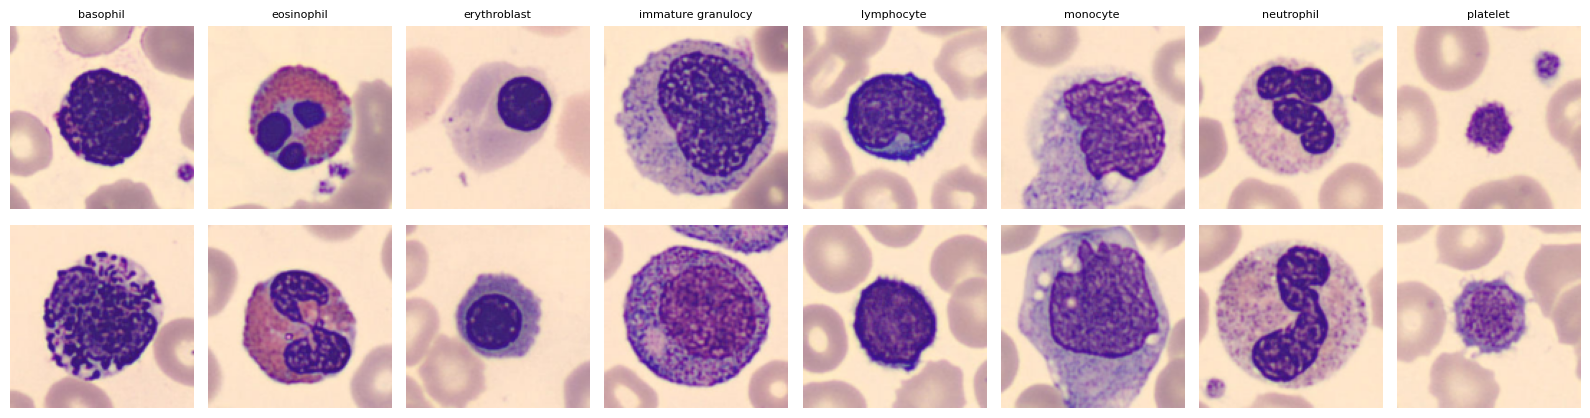

In [4]:
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for c in range(n_classes):
    idx = np.flatnonzero(y_tr == c)[:2]
    for r, i in enumerate(idx):
        ax[r, c].imshow(imgs_tr[i]); ax[r, c].axis("off")
        if r == 0: ax[r, c].set_title(class_names[c][:18], fontsize=8)
plt.tight_layout(); plt.savefig("results/samples.png", dpi=150); plt.show()

## 2. HOG feature extraction
Images → grayscale → HOG (9 orientations, 8×8 pixels/cell, 2×2 cells/block, L2-Hys). Feature order of `skimage.hog` is `(block_row, block_col, cell_row, cell_col, orientation)`, which lets us map selected features back to image locations later.

In [5]:
def hog_one(img):
    g = rgb2gray(img) if img.ndim == 3 else img / 255.0
    return hog(g, orientations=CFG["orientations"], pixels_per_cell=CFG["ppc"],
               cells_per_block=CFG["cpb"], block_norm=CFG["block_norm"],
               feature_vector=True).astype(np.float32)

def extract(imgs):
    return np.vstack(Parallel(n_jobs=-1, batch_size=64)(delayed(hog_one)(im) for im in imgs))

t0 = time.time(); X_tr_raw = extract(imgs_tr); t_hog_tr = time.time() - t0
t0 = time.time(); X_va_raw = extract(imgs_va); t_hog_va = time.time() - t0
t0 = time.time(); X_te_raw = extract(imgs_te); t_hog_te = time.time() - t0
D = X_tr_raw.shape[1]
print(f"HOG dimension D = {D}  | extraction time (train/val/test): {t_hog_tr:.1f}s / {t_hog_va:.1f}s / {t_hog_te:.1f}s")

# Standardise with statistics from the TRAIN set only
scaler = StandardScaler().fit(X_tr_raw)
X_tr, X_va, X_te = [scaler.transform(a).astype(np.float32) for a in (X_tr_raw, X_va_raw, X_te_raw)]

HOG dimension D = 8100  | extraction time (train/val/test): 97.5s / 13.7s / 27.4s


## 3. Evaluation helpers
All the metrics requested in Table 2. Specificity is computed **one-vs-rest per class and macro-averaged** (TN / (TN + FP) per class, then the unweighted mean).

In [6]:
def specificity_macro(y, p, labels):
    cm = confusion_matrix(y, p, labels=labels); sp = []
    for i in range(len(labels)):
        fp = cm[:, i].sum() - cm[i, i]
        tn = cm.sum() - cm[i, :].sum() - cm[:, i].sum() + cm[i, i]
        sp.append(tn / (tn + fp) if (tn + fp) > 0 else 0.0)
    return float(np.mean(sp))

def all_metrics(y, p):
    L = list(range(n_classes))
    return {
        "Accuracy (%)":            100 * accuracy_score(y, p),
        "Precision (Macro, %)":    100 * precision_score(y, p, average="macro", zero_division=0),
        "Recall (Macro, %)":       100 * recall_score(y, p, average="macro", zero_division=0),
        "Macro-F1 (%)":            100 * f1_score(y, p, average="macro", zero_division=0),
        "Weighted-F1 (%)":         100 * f1_score(y, p, average="weighted", zero_division=0),
        "Balanced accuracy (%)":   100 * balanced_accuracy_score(y, p),
        "Specificity (Macro, %)":  100 * specificity_macro(y, p, L),
        "Cohen's kappa":           cohen_kappa_score(y, p),
        "Matthews corr. coeff.":   matthews_corrcoef(y, p),
    }

def fit_svm(Xa, ya, C):
    t0 = time.time()
    clf = SVC(C=C, kernel="rbf", gamma="scale", random_state=SEED).fit(Xa, ya)
    return clf, time.time() - t0

def tune_svm(Xa, ya, Xb, yb, tag):
    """Pick C on the VALIDATION set by macro-F1. Returns best model + log."""
    best, log = None, []
    for C in CFG["C_grid"]:
        clf, t_fit = fit_svm(Xa, ya, C)
        t0 = time.time(); p = clf.predict(Xb); t_pred = time.time() - t0
        f1 = f1_score(yb, p, average="macro")
        log.append(dict(model=tag, C=C, val_macroF1=100 * f1, fit_s=t_fit, val_pred_s=t_pred))
        print(f"[{tag}] C={C:<4} val macro-F1={100*f1:.2f}  fit={t_fit:.1f}s")
        if best is None or f1 > best["f1"]:
            best = dict(clf=clf, C=C, f1=f1, fit_s=t_fit)
    return best, pd.DataFrame(log)

## 4. Baseline: HOG + SVM (all features)

In [ ]:
base, base_log = tune_svm(X_tr, y_tr, X_va, y_va, "HOG+SVM")
print("\nBaseline selected C =", base["C"])

## 5. Genetic Algorithm for HOG feature selection

**Chromosome:** binary vector of length *D* (1 = keep feature).  
**Fitness:** `validation macro-F1 − λ · (n_selected / D)` using an RBF-SVM trained on a stratified training subset and scored on a stratified validation subset (for speed).  
**Operators:** random-density initialisation, tournament selection (k=3), uniform crossover (p=0.8), bit-flip mutation (p<sub>m</sub> per gene), elitism (2).

In [ ]:
# Stratified subsets used ONLY for GA fitness evaluation
sub_tr, _ = train_test_split(np.arange(len(y_tr)), train_size=CFG["ga_train_n"], stratify=y_tr, random_state=SEED)
sub_va, _ = train_test_split(np.arange(len(y_va)), train_size=min(CFG["ga_val_n"], len(y_va) - 1), stratify=y_va, random_state=SEED)
Xg_tr, yg_tr, Xg_va, yg_va = X_tr[sub_tr], y_tr[sub_tr], X_va[sub_va], y_va[sub_va]

def fitness(mask):
    idx = np.flatnonzero(mask)
    if idx.size < 20:
        return -1.0, 0.0
    clf = SVC(C=CFG["ga_C"], kernel="rbf", gamma="scale", random_state=SEED).fit(Xg_tr[:, idx], yg_tr)
    f1 = f1_score(yg_va, clf.predict(Xg_va[:, idx]), average="macro")
    return f1 - CFG["lam"] * idx.size / mask.size, f1

def eval_population(pop):
    res = Parallel(n_jobs=-1)(delayed(fitness)(m) for m in pop)
    return np.array([r[0] for r in res]), np.array([r[1] for r in res])

def run_ga(pop_size, pm, gens=None, seed=SEED):
    gens = gens or CFG["ga_gens"]
    rng = np.random.default_rng(seed)
    t0 = time.time()
    # --- population initialisation: each individual has its own random keep-density ---
    dens = rng.uniform(0.1, 0.6, size=pop_size)
    pop = rng.random((pop_size, D)) < dens[:, None]
    fit, f1s = eval_population(pop)
    hist = []
    for g in range(gens + 1):
        b = int(np.argmax(fit))
        hist.append(dict(gen=g, best_fitness=fit[b], mean_fitness=fit.mean(), best_f1=f1s[b],
                         best_nfeat=int(pop[b].sum()), mean_nfeat=float(pop.sum(1).mean())))
        print(f"  gen {g:>2}: best fit={fit[b]:.4f} (F1={f1s[b]:.4f}, {int(pop[b].sum())} feats) mean fit={fit.mean():.4f}")
        if g == gens: break
        # --- elitism ---
        order = np.argsort(-fit)[:CFG["n_elite"]]
        elites, e_fit, e_f1 = pop[order], fit[order], f1s[order]
        # --- selection + crossover + mutation ---
        def tournament():
            c = rng.integers(0, pop_size, size=CFG["tournament_k"])
            return pop[c[np.argmax(fit[c])]]
        kids = []
        while len(kids) < pop_size - CFG["n_elite"]:
            p1, p2 = tournament(), tournament()
            if rng.random() < CFG["p_crossover"]:
                sel = rng.random(D) < 0.5                       # uniform crossover
                c1, c2 = np.where(sel, p1, p2), np.where(sel, p2, p1)
            else:
                c1, c2 = p1.copy(), p2.copy()
            for c in (c1, c2):
                kids.append(np.logical_xor(c, rng.random(D) < pm))  # bit-flip mutation
        kids = np.array(kids[:pop_size - CFG["n_elite"]])
        k_fit, k_f1 = eval_population(kids)
        pop = np.vstack([elites, kids]); fit = np.concatenate([e_fit, k_fit]); f1s = np.concatenate([e_f1, k_f1])
    best = int(np.argmax(fit))
    return pop[best].copy(), pd.DataFrame(hist), time.time() - t0

In [ ]:
ga_runs = {}
for name, s in GA_SETTINGS.items():
    print(f"\n=== {name} ===")
    mask, hist, t_ga = run_ga(s["pop"], s["pm"])
    ga_runs[name] = dict(mask=mask, hist=hist, ga_time=t_ga, **s)
    print(f"GA time: {t_ga:.1f}s | selected {mask.sum()} / {D} features")

## 6. Plot GA fitness across generations

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for name, r in ga_runs.items():
    h = r["hist"]
    ax[0].plot(h.gen, h.best_fitness, marker="o", label=f"{name} – best")
    ax[0].plot(h.gen, h.mean_fitness, ls="--", alpha=.6, label=f"{name} – mean")
    ax[1].plot(h.gen, h.best_f1, marker="o", label=name)
    ax[2].plot(h.gen, h.best_nfeat, marker="o", label=name)
ax[0].set(title="GA fitness vs. generation", xlabel="Generation", ylabel="Fitness (macro-F1 − λ·fraction)")
ax[1].set(title="Best individual: GA-subset validation macro-F1", xlabel="Generation", ylabel="Macro-F1")
ax[2].set(title="Best individual: # selected features", xlabel="Generation", ylabel="# features")
ax[2].axhline(D, color="k", ls=":", label=f"All HOG features ({D})")
for a in ax: a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("results/ga_fitness.png", dpi=150); plt.show()

## 7. Model selection on the validation set (no test data)
Retrain an SVM on the **full** training set with each GA mask, score on the **full** validation set, and keep the GA setting with the best penalised validation fitness. Then tune `C` on the validation set.

In [ ]:
rows = []
for name, r in ga_runs.items():
    idx = np.flatnonzero(r["mask"])
    clf, t_fit = fit_svm(X_tr[:, idx], y_tr, CFG["ga_C"])
    f1 = f1_score(y_va, clf.predict(X_va[:, idx]), average="macro")
    r["val_f1_full"] = f1
    r["val_fitness_full"] = f1 - CFG["lam"] * idx.size / D
    rows.append({"GA setting": name, "Population": r["pop"], "Mutation prob.": r["pm"],
                 "Best GA fitness (subset)": r["hist"].best_fitness.iloc[-1],
                 "# features": idx.size, "% kept": 100 * idx.size / D,
                 "Val macro-F1 (full, %)": 100 * f1, "Val fitness (full)": r["val_fitness_full"],
                 "GA time (s)": r["ga_time"]})
table3 = pd.DataFrame(rows).round(4)
best_name = max(ga_runs, key=lambda k: ga_runs[k]["val_fitness_full"])
print("Selected GA setting:", best_name)
table3

In [ ]:
mask = ga_runs[best_name]["mask"]; sel = np.flatnonzero(mask)
gaf, gaf_log = tune_svm(X_tr[:, sel], y_tr, X_va[:, sel], y_va, "GA-HOG+SVM")
print("\nGA-HOG selected C =", gaf["C"], "| features:", sel.size, "/", D)

## 8. Feature count before vs. after, and where the GA looks

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
ax[0].bar(["HOG (all)", "GA-HOG"], [D, sel.size], color=["#888", "#2a9d8f"])
for i, v in enumerate([D, sel.size]): ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set(title="Number of features: before vs. after", ylabel="# features")

# Map the mask back to HOG block positions: (block_row, block_col, cell_r, cell_c, orient)
n_by = (imgs_tr.shape[1] // CFG["ppc"][0] - CFG["cpb"][0]) + 1
heat = mask.reshape(n_by, n_by, CFG["cpb"][0], CFG["cpb"][1], CFG["orientations"]).mean(axis=(2, 3, 4))
im = ax[1].imshow(heat, cmap="viridis", vmin=0, vmax=1); ax[1].set_title("Fraction of features kept per HOG block")
plt.colorbar(im, ax=ax[1])
orient_keep = mask.reshape(-1, CFG["orientations"]).mean(axis=0)
ax[2].bar(range(CFG["orientations"]), orient_keep); ax[2].set(title="Fraction kept per orientation bin", xlabel="Orientation bin", ylim=(0, 1))
plt.tight_layout(); plt.savefig("results/feature_selection.png", dpi=150); plt.show()

## 9. FINAL evaluation on the test set (first and only use)

In [ ]:
t0 = time.time(); p_base = base["clf"].predict(X_te); t_pred_base = time.time() - t0
t0 = time.time(); p_ga   = gaf["clf"].predict(X_te[:, sel]); t_pred_ga = time.time() - t0

m_base, m_ga = all_metrics(y_te, p_base), all_metrics(y_te, p_ga)
table2 = pd.DataFrame({"HOG + SVM (Baseline)": m_base, "GA-HOG + SVM (Proposed)": m_ga})
table2["Improvement"] = table2.iloc[:, 1] - table2.iloc[:, 0]
table2 = table2.round(4)
table2.index.name = "Metric"
table2.to_csv("results/table2_performance.csv")
table2

In [ ]:
table1 = pd.DataFrame([
    ["Medical dataset", CFG["dataset"], CFG["dataset"]],
    ["Image resolution", f"{CFG['size']} × {CFG['size']}", f"{CFG['size']} × {CFG['size']}"],
    ["HOG orientations", CFG["orientations"], CFG["orientations"]],
    ["Pixels per cell", "8 × 8", "8 × 8"],
    ["Cells per block", "2 × 2", "2 × 2"],
    ["Block normalization", CFG["block_norm"], CFG["block_norm"]],
    ["Feature selection", "None", f"Genetic Algorithm ({best_name})"],
    ["Classifier", "SVM", "SVM"],
    ["SVM kernel", "RBF", "RBF"],
    ["Hyperparameter tuning", f"Validation set (C∈{CFG['C_grid']} → C={base['C']})", f"Validation set (C∈{CFG['C_grid']} → C={gaf['C']})"],
    ["Data split", "Identical fixed (official MedMNIST)", "Identical fixed (official MedMNIST)"],
    ["Random seed", SEED, SEED],
    ["# features", D, int(sel.size)],
], columns=["Parameter", "Baseline: HOG + SVM", "Proposed: GA-HOG + SVM"])
table1.to_csv("results/table1_config.csv", index=False)
table3.to_csv("results/table3_ga_settings.csv", index=False)
table1

In [ ]:
t_ga_sel = ga_runs[best_name]["ga_time"]
table4 = pd.DataFrame({
    "HOG + SVM": {"Feature dimension": D, "HOG extraction (s, train+val+test)": t_hog_tr + t_hog_va + t_hog_te,
                  "GA search (s)": 0.0, "Final SVM training (s)": base["fit_s"],
                  "Test inference (s)": t_pred_base,
                  "Total (s)": t_hog_tr + t_hog_va + t_hog_te + base["fit_s"] + t_pred_base},
    "GA-HOG + SVM": {"Feature dimension": int(sel.size), "HOG extraction (s, train+val+test)": t_hog_tr + t_hog_va + t_hog_te,
                     "GA search (s)": t_ga_sel, "Final SVM training (s)": gaf["fit_s"],
                     "Test inference (s)": t_pred_ga,
                     "Total (s)": t_hog_tr + t_hog_va + t_hog_te + t_ga_sel + gaf["fit_s"] + t_pred_ga},
}).round(3)
table4.to_csv("results/table4_time.csv")
table4

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, p, t in zip(ax, (p_base, p_ga), ("HOG + SVM", f"GA-HOG + SVM ({sel.size} feats)")):
    ConfusionMatrixDisplay(confusion_matrix(y_te, p), display_labels=[c[:10] for c in class_names]).plot(ax=a, colorbar=False, xticks_rotation=45)
    a.set_title(t)
plt.tight_layout(); plt.savefig("results/confusion_matrices.png", dpi=150); plt.show()

# Bar chart of key metrics
keys = ["Accuracy (%)", "Macro-F1 (%)", "Balanced accuracy (%)"]
x = np.arange(len(keys)); w = .35
plt.figure(figsize=(7, 4))
plt.bar(x - w/2, [m_base[k] for k in keys], w, label="HOG + SVM")
plt.bar(x + w/2, [m_ga[k] for k in keys], w, label="GA-HOG + SVM")
plt.xticks(x, keys); plt.ylabel("%"); plt.legend(); plt.title("Test-set comparison"); plt.ylim(0, 100)
plt.tight_layout(); plt.savefig("results/metric_comparison.png", dpi=150); plt.show()

## 10. Auto-generated result summary

In [ ]:
dF1 = m_ga["Macro-F1 (%)"] - m_base["Macro-F1 (%)"]
red = 100 * (1 - sel.size / D)
verdict = "IMPROVED" if dF1 > 0.1 else ("MATCHED (within ±0.1 pt)" if dF1 >= -0.1 else "DID NOT IMPROVE")
print(f"Dataset: {CFG['dataset']} ({CFG['size']}x{CFG['size']}), {n_classes} classes")
print(f"Features: {D} -> {sel.size}  ({red:.1f}% reduction)")
print(f"Test macro-F1:  baseline {m_base['Macro-F1 (%)']:.2f}  vs  GA-HOG {m_ga['Macro-F1 (%)']:.2f}  (Δ = {dF1:+.2f} pts)")
print(f"Test accuracy:  baseline {m_base['Accuracy (%)']:.2f}  vs  GA-HOG {m_ga['Accuracy (%)']:.2f}")
print(f"Balanced acc.:  baseline {m_base['Balanced accuracy (%)']:.2f}  vs  GA-HOG {m_ga['Balanced accuracy (%)']:.2f}")
print(f"SVM train time: {base['fit_s']:.1f}s -> {gaf['fit_s']:.1f}s | GA search cost: {t_ga_sel:.1f}s")
print(f"=> GA feature selection {verdict} classification performance while cutting dimensionality by {red:.1f}%.")

## 11. Discussion

**Did GA-based selection help?** Read the Section 10 summary and Table 2 for the actual outcome of your run. Typically on HOG features the GA gives a large dimensionality reduction (tens of percent) with accuracy/macro-F1 that is *comparable* to the baseline, and sometimes slightly better because noisy, redundant or uninformative orientation bins and background blocks are dropped. Report whichever you observe — a small gain, a tie, or a small loss are all legitimate findings, but only differences larger than the run-to-run noise should be called "improvement" (repeat with 3–5 seeds and report mean ± std if you want to claim significance).

**Strengths**
- Directly optimises the metric we care about (validation macro-F1) and a sparsity penalty simultaneously — a wrapper method that accounts for the interaction between features and the RBF-SVM.
- Produces an interpretable mask: the block heat-map shows which image regions and gradient orientations matter (e.g. cell-centre blocks for blood-cell morphology).
- Fewer features ⇒ smaller SVM input, faster final training and inference, less memory.
- Model-agnostic and needs no gradients.

**Limitations**
- High-dimensional search space (D ≈ 8,100 bits) vs. a small number of generations/population ⇒ the GA is far from converged; results depend on seed, population size and mutation rate.
- Fitness is estimated on subsets for speed, so it is a noisy proxy of full-data validation performance; the GA can over-fit the validation subset (hence the final full-validation check and a untouched test set).
- The penalty weight λ trades accuracy for sparsity and must be tuned.
- HOG itself is a hand-crafted feature; a CNN will generally beat both pipelines on BloodMNIST.

**Computational cost**
- The GA needs `population × (generations + 1)` SVM fits (see Table 3/4 "GA search"), which dominates the total pipeline time. The cost is paid **once**; afterwards training and inference use fewer features.
- Costs can be reduced by evaluating fitness on smaller subsets, grouping features by HOG block (chromosome length 225 instead of 8,100), using a linear SVM inside the GA, or parallelising across more cores/GPUs.

**Ethical / validity note** — all model selection (SVM `C`, GA setting, GA masks) used train/validation data only; the test set was evaluated once in Section 9.